In [2]:
# Generic
import numpy as np
from numpy import *
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# Torch
import torch
from torch import nn
import torch.nn.functional as F
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import Dataset,DataLoader
from torchvision import models, transforms
from torchvision.models import vgg16, VGG16_Weights
import torch.optim as optim
from torch.utils.data import Subset

# Custom dataset
from dataset import ImageDataset

# Set the seed of Torch
#seed = 42
#random.seed(seed)
#np.random.seed(seed)
#torch.manual_seed(seed)

# Check for GPU availability

In [3]:
import torch
import sys
import os

print("Python executable:", sys.executable)
print("PyTorch version:", torch.__version__)
print("CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
print("Hostname:", os.uname().nodename)

Python executable: /opt/scopia/bin/python3.11
PyTorch version: 2.5.1+cu121
CUDA version: 12.1
CUDA available: True
GPU count: 2
Hostname: fc76a60b252b


# Dataset loading

In [4]:
info = pd.DataFrame(
    np.load("/home/jovyan/work/HWD+/Datasets/WriterInfo.npy", allow_pickle=True)
)

labels = info.drop(columns=[1,2, 3, 4, 5, 6, 7, 8])
labels = labels.rename(columns={
    0: "label",
})

images=np.load(r"/home/jovyan/work/HWD+/Datasets/Images(500x500).npy")

labels["image"] = list(images)

labels_array = labels["label"].to_numpy()
dataset = ImageDataset(images, labels_array)

# Splitting and data loader

## Splitting

In [5]:

# Get labels
labels = dataset.labels

# First split: 80% training, 20% temporary
train_idx, temp_idx = train_test_split(
    range(len(dataset)),
    test_size=0.2,
    stratify=labels,
    random_state=42
)

# Get labels for temporary set
temp_labels = [labels[i] for i in temp_idx]

# Second split: 10% validation, 10% test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    stratify=temp_labels,
    random_state=42
)

# Create PyTorch subsets
train = Subset(dataset, train_idx)
val = Subset(dataset, val_idx)
test = Subset(dataset, test_idx)

In [6]:
print(f'Training set length: {len(train)}')
print(f'Validation set length: {len(val)}')
print(f'Test set length: {len(test)}')

print(type(train))

Training set length: 10864
Validation set length: 1358
Test set length: 1358
<class 'torch.utils.data.dataset.Subset'>


## Data Loader

In [7]:
# Define batch size to avoid RAM problems
batch_size = 10

# Shuffle to avoid integrating some "order induced" bias
train_loader = DataLoader(
    dataset=train,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    dataset=val,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    dataset=test,
    batch_size=batch_size,
    shuffle=False
)

# VGG16 NN

## Hyper Parameters

In [8]:
# Hyper Parameters
learning_rate=0.1
Epochs=10 # Number of iterations

## VGG16

In [9]:
from models.vgg16_modified import VGG16Model

In [10]:
# Number of classes
num_classes = 10

# Choose device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Instantiate model
vgg = VGG16Model(num_classes=num_classes)

# Move model to device
vgg = vgg.to(device)

## Training configuration

In [11]:
# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizerimport time
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, vgg.parameters()),
    lr=0.0001
)

In [12]:
import time

num_epochs = 15

# Start total timer
total_start_time = time.time()

for epoch in range(num_epochs):
    # Start epoch timer
    epoch_start_time = time.time()

    # Training
    vgg.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device).long()
        optimizer.zero_grad()

        outputs = vgg(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)
    train_loss /= train_total
    train_accuracy = train_correct / train_total

    # Validation
    vgg.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device).long()

            outputs = vgg(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_accuracy = val_correct / val_total

    # End epoch timer
    epoch_time = time.time() - epoch_start_time

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f} | "
        f"Time: {epoch_time:.2f} seconds"
    )

# End total timer
total_time = time.time() - total_start_time

print(f"\nTotal training time: {total_time:.2f} seconds")
print(f"Total training time: {total_time / 60:.2f} minutes")

Epoch [1/15] Train Loss: 3.0678 | Train Accuracy: 0.6539 | Val Loss: 0.3499 | Val Accuracy: 0.8873 | Time: 49.35 seconds
Epoch [2/15] Train Loss: 0.8526 | Train Accuracy: 0.8153 | Val Loss: 0.2670 | Val Accuracy: 0.9300 | Time: 47.13 seconds
Epoch [3/15] Train Loss: 0.8065 | Train Accuracy: 0.8608 | Val Loss: 0.2761 | Val Accuracy: 0.9381 | Time: 46.90 seconds
Epoch [4/15] Train Loss: 0.7169 | Train Accuracy: 0.8859 | Val Loss: 0.2079 | Val Accuracy: 0.9418 | Time: 47.53 seconds
Epoch [5/15] Train Loss: 0.5027 | Train Accuracy: 0.9149 | Val Loss: 0.2235 | Val Accuracy: 0.9448 | Time: 46.97 seconds
Epoch [6/15] Train Loss: 0.5114 | Train Accuracy: 0.9238 | Val Loss: 0.2699 | Val Accuracy: 0.9529 | Time: 46.97 seconds
Epoch [7/15] Train Loss: 0.6874 | Train Accuracy: 0.9216 | Val Loss: 0.3906 | Val Accuracy: 0.9536 | Time: 47.02 seconds
Epoch [8/15] Train Loss: 0.6769 | Train Accuracy: 0.9362 | Val Loss: 0.2104 | Val Accuracy: 0.9617 | Time: 47.07 seconds
Epoch [9/15] Train Loss: 0.3710 

In [13]:
torch.save(
    vgg.state_dict(),
    "/home/jovyan/work/HWD+/saved_models/vgg16_trained.pth"
)

In [14]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vgg_loaded = VGG16Model(num_classes=10, pretrained=False)

# Load trained weights
vgg_loaded.load_state_dict(
    torch.load(
        "/home/jovyan/work/HWD+/saved_models/vgg16_trained.pth",
        map_location=device,
        weights_only=True
    )
)

vgg_loaded=vgg_loaded.to(device)

In [15]:
from functions.evaluate import evaluate_model

test_accuracy = evaluate_model(
    model=vgg_loaded,
    loader=test_loader,
    device=device
)

Test Accuracy: 0.9772
Test Accuracy: 97.72%


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.008305506..4.4563036].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.008305506..4.4563036].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.008305506..4.4563036].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.008305506..4.4563036].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.008305506..4.4563036].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.008305506..4.4563036].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got rang

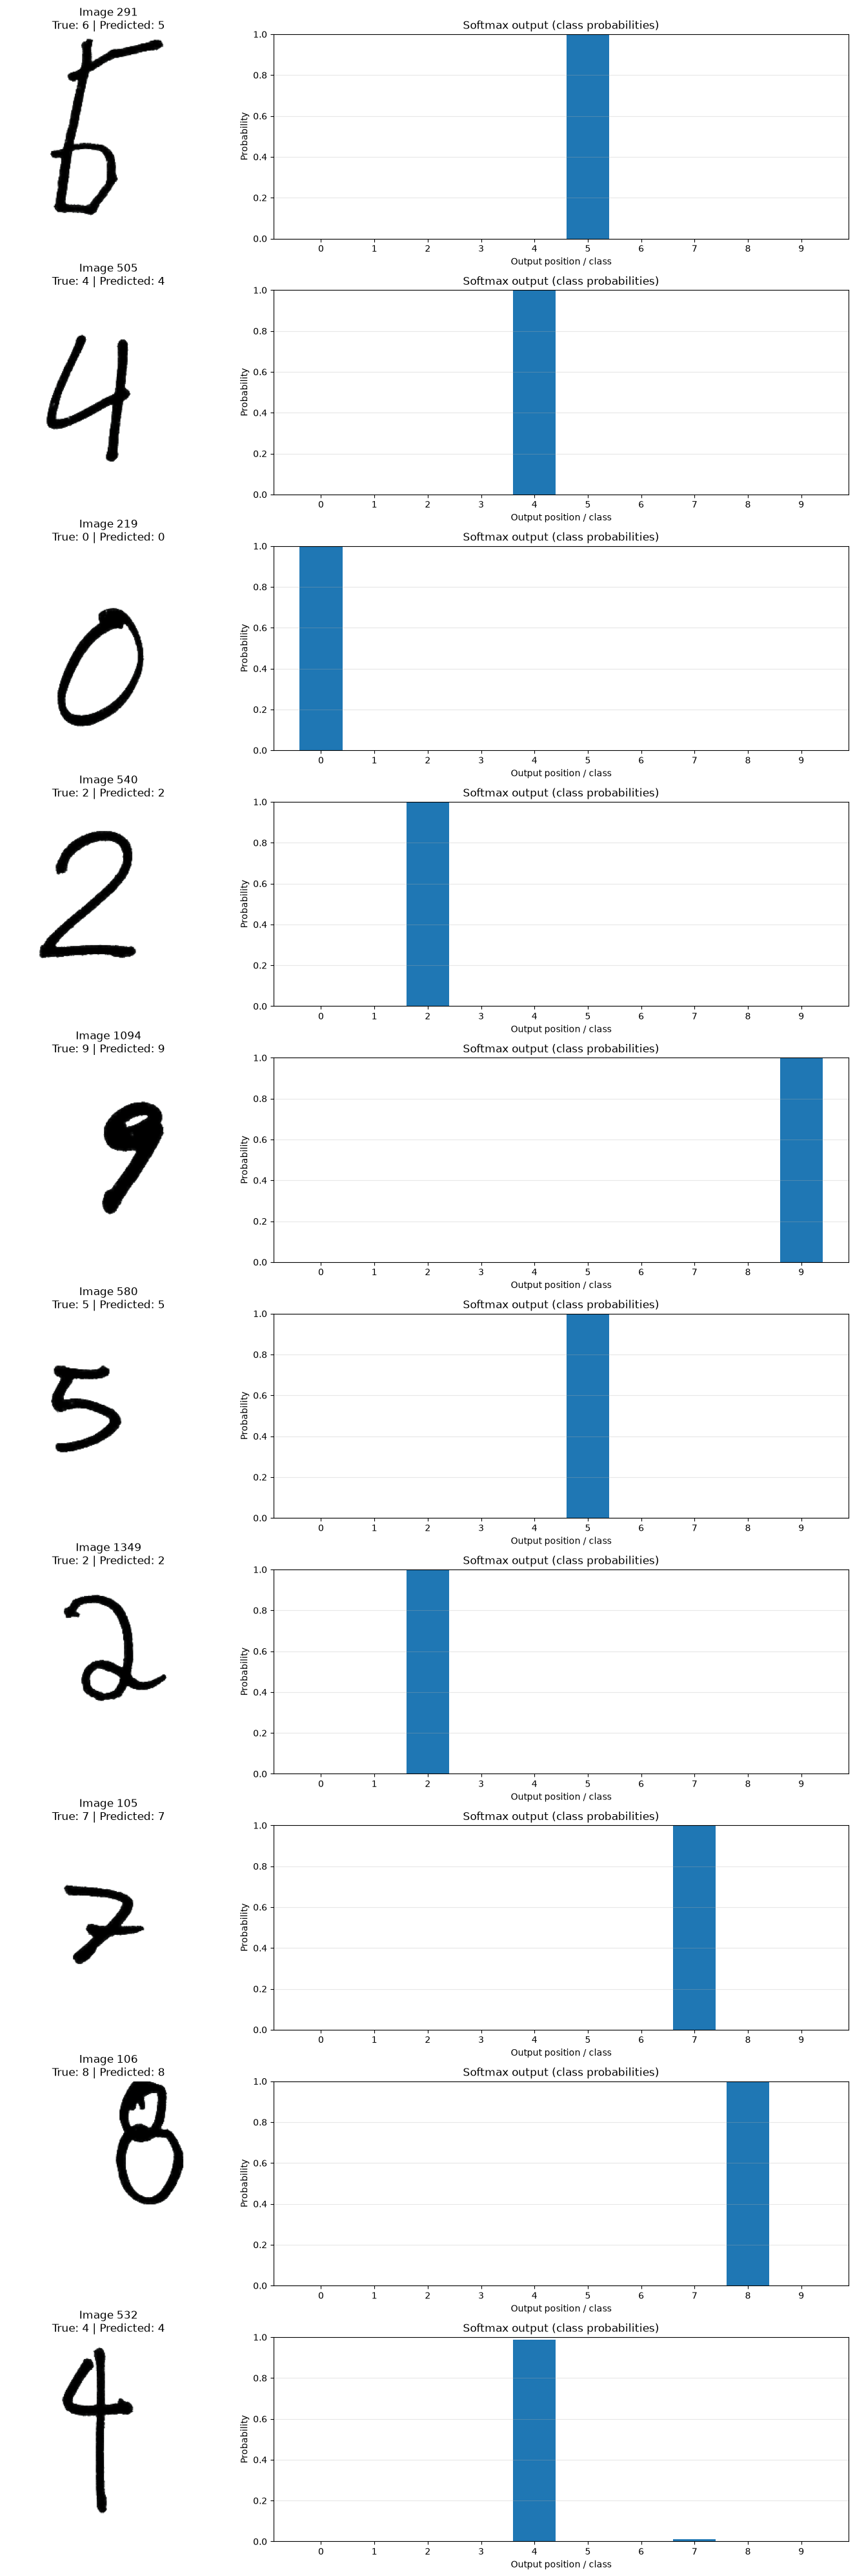

In [16]:
import torch
import matplotlib.pyplot as plt
import random

# How many test images to display
num_images = 10

# Pick several random test images
indices = random.sample(range(len(test)), num_images)

fig, axes = plt.subplots(
    num_images, 2,
    figsize=(14, 4 * num_images),
    gridspec_kw={"width_ratios": [1, 2]}
)

for i, idx in enumerate(indices):
    # Get image and true label
    image, label = test[idx]

    # Prepare image for VGG
    input_image = image.unsqueeze(0).to(device)

    # Predict
    vgg.eval()
    with torch.no_grad():
        output = vgg(input_image)
        probabilities = torch.softmax(output, dim=1)[0]

        prediction = output.argmax(dim=1).item()
    
    # Convert probabilities to NumPy
    values = probabilities.cpu().numpy()
    # Convert image from Tensor (C, H, W) to NumPy (H, W, C)
    img = image.detach().cpu().permute(1, 2, 0).numpy()
    # Scale pixel values from [0, 255] to [0, 1]
    img = img / 255.0

    
    # Display image
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(
        f"Image {idx}\nTrue: {label.item()} | Predicted: {prediction}"
    )
    axes[i, 0].axis("off")
    
    # Display softmax probabilities
    positions = range(len(values))
    
    axes[i, 1].bar(positions, values)
    axes[i, 1].set_title("Softmax output (class probabilities)")
    axes[i, 1].set_xlabel("Output position / class")
    axes[i, 1].set_ylabel("Probability")
    axes[i, 1].set_xticks(list(positions))
    axes[i, 1].set_ylim(0, 1)
    axes[i, 1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()